   area     price
0  7420  13300000
1  8960  12250000
2  9960  12250000
3  7500  12215000
4  7420  11410000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   area    545 non-null    int64
 1   price   545 non-null    int64
dtypes: int64(2)
memory usage: 8.6 KB
None
               area         price
count    545.000000  5.450000e+02
mean    5150.541284  4.766729e+06
std     2170.141023  1.870440e+06
min     1650.000000  1.750000e+06
25%     3600.000000  3.430000e+06
50%     4600.000000  4.340000e+06
75%     6360.000000  5.740000e+06
max    16200.000000  1.330000e+07
area     0
price    0
dtype: int64
           area     price
area   1.000000  0.535997
price  0.535997  1.000000


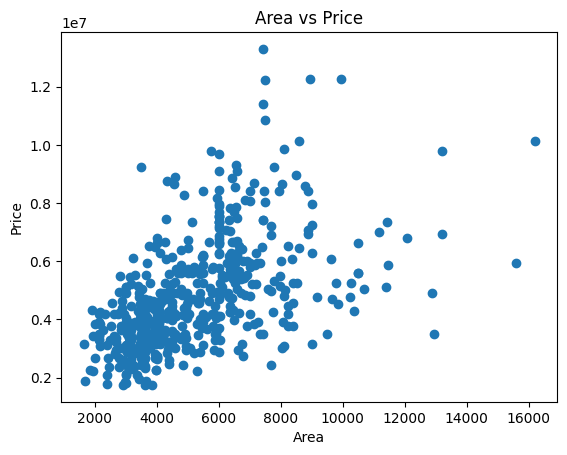

In [4]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv('../data/Housing.csv')[['area', 'price']]

print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.corr())

plt.scatter(df['area'], df['price'])
plt.xlabel("Area"); plt.ylabel("Price"); plt.title("Area vs Price")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = df[["area"]]    
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 425.72984193878284
Intercept: 2512254.2639593435


In [7]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R²  :", r2_score(y_test, pred))

comparison = pd.DataFrame({"area": X_test["area"], "actual": y_test, "predicted": pred.round()})
print(comparison.head(10))

MAE : 1474748.1337969352
RMSE: 1917103.7021424233
R²  : 0.27287851871974644
     area   actual  predicted
316  5900  4060000  5024060.0
77   6500  6650000  5279498.0
360  4040  3710000  4232203.0
90   5000  6440000  4640903.0
493  3960  2800000  4198144.0
209  6720  4900000  5373159.0
176  8520  5250000  6139473.0
249  4990  4543000  4636646.0
516  3240  2450000  3891619.0
426  2700  3353000  3661725.0


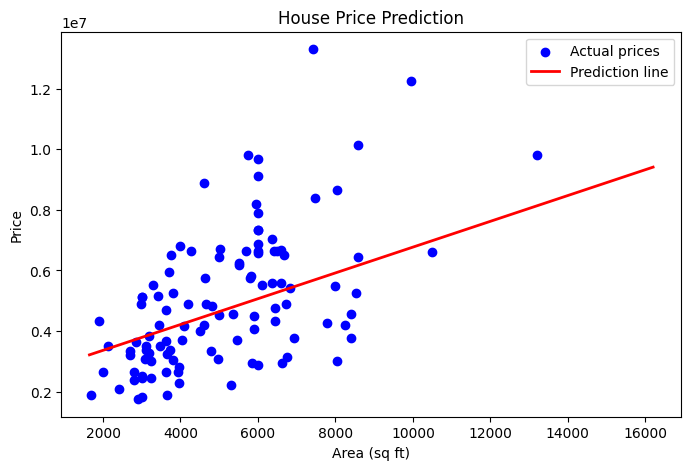

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="blue", label="Actual prices")
line_x = X.sort_values("area")
plt.plot(line_x, model.predict(line_x), color="red", linewidth=2, label="Prediction line")
plt.xlabel("Area (sq ft)"); plt.ylabel("Price")
plt.title("House Price Prediction"); plt.legend()
plt.savefig("results.png", dpi=150)
plt.show()

In [9]:
import joblib
joblib.dump(model, "model.joblib")

['model.joblib']